# Kesit İstatistik — Güvenilir model değerlendirme

Kurulum: `python -m pip install -r requirements.txt`

Python 3.11+ ve Jupyter/VS Code ile aç. Önce kurulum hücresini, sonra ders hücrelerini çalıştır. Hazır çıktılar doğrulanan çalıştırmadan alınmıştır; kodu değiştirdiğinde hücreyi yeniden çalıştır. Her ders kendi sentetik verisini üretir. İnternet/API/şirket verisi gerektirmez.


## İç içe çapraz doğrulama ve seçim yanlılığı

Seçtiğim en iyi doğrulama skoru neden iyimser olabilir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** İç seçim skoruyla dış kat sonuçlarını ayır.

**Yorum sınırı:** Ölçekleme pipeline içindedir. İç içe CV belirlenen arama prosedürünü değerlendirir, her veri sorununu çözmez.

**Alıştırma:** C adaylarına 10 ve 100 ekle; seçim skorunu dış sonuçla karşılaştır.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


   dis_kat  ic_secim_skoru  dis_test_skoru
0        1        0.900000        0.850000
1        2        0.872222        0.866667
2        3        0.894444        0.916667
3        4        0.916667        0.833333
Dış ortalama: 0.8666666666666667


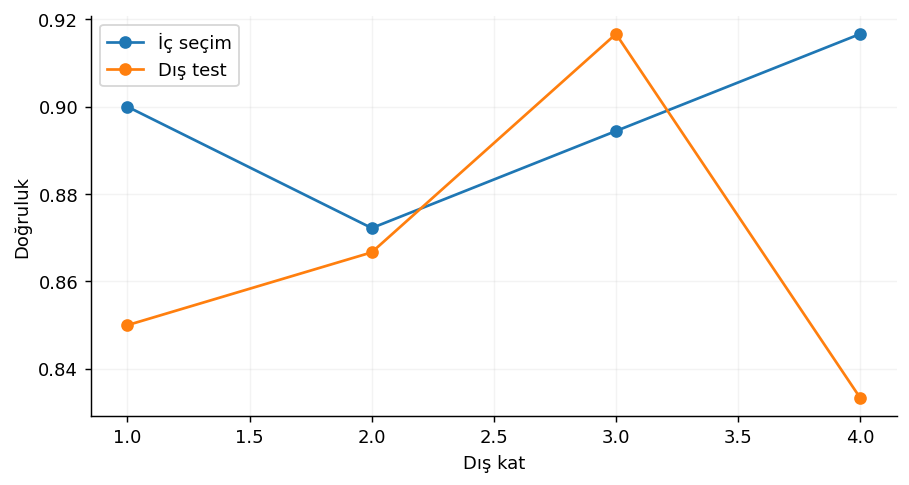

In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.svm import SVC
X,y=make_classification(n_samples=240,n_features=8,n_informative=4,random_state=7);outer=StratifiedKFold(4,shuffle=True,random_state=7);rows=[]
for fold,(tr,te) in enumerate(outer.split(X,y),1):
 search=GridSearchCV(make_pipeline(StandardScaler(),SVC(kernel='rbf')),{'svc__C':[.1,1,10],'svc__gamma':[.01,.1,1]},cv=3,scoring='accuracy');search.fit(X[tr],y[tr]);rows.append([fold,search.best_score_,search.score(X[te],y[te])])
t=pd.DataFrame(rows,columns=['dis_kat','ic_secim_skoru','dis_test_skoru']);print(t);print('Dış ortalama:',t.dis_test_skoru.mean());plt.plot(t.dis_kat,t.ic_secim_skoru,'o-',label='İç seçim');plt.plot(t.dis_kat,t.dis_test_skoru,'o-',label='Dış test');plt.xlabel('Dış kat');plt.ylabel('Doğruluk');plt.legend()

## ROC, precision–recall ve dengesizlik

Nadir olayda ROC iyi görünürken alarm yükü nasıl olabilir?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** ROC-AUC yanında PR ve taban oranını raporla.

**Yorum sınırı:** Average precision bir eşikte precision değildir; değerlendirme bağımsız testte yapılır.

**Alıştırma:** Pozitif payını .1’den .02’ye indir; ROC ve AP değişimini incele.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'taban': np.float64(0.105), 'ROC_AUC': 0.9417693831101651, 'AP': 0.8204804018729897}


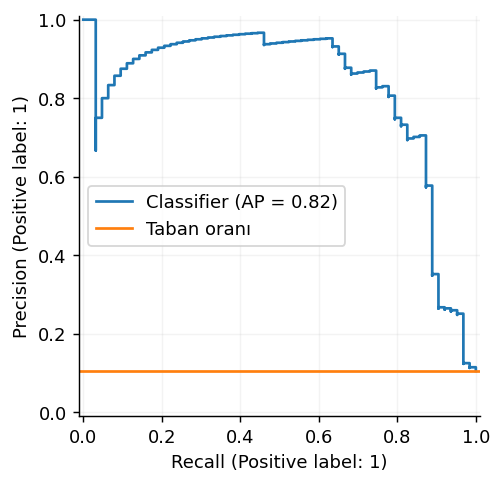

In [106]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
X,y=make_classification(n_samples=1500,n_features=6,n_informative=3,weights=[.9,.1],random_state=7);a,b,c,d=train_test_split(X,y,test_size=.4,stratify=y,random_state=7);m=make_pipeline(StandardScaler(),LogisticRegression());m.fit(a,c);p=m.predict_proba(b)[:,1];print({'taban':d.mean(),'ROC_AUC':roc_auc_score(d,p),'AP':average_precision_score(d,p)})
PrecisionRecallDisplay.from_predictions(d,p,ax=plt.gca());plt.axhline(d.mean(),c='tab:orange',label='Taban oranı');plt.legend()

## Kalibrasyon, Brier ve güvenilirlik diyagramı

Kalibratörü test verisinden öğrenmeden nasıl sınarım?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Kalibrasyon eğrilerini ve Brier’ı aynı bağımsız testte kıyasla.

**Yorum sınırı:** CalibratedClassifierCV eğitim içinde CV kullanır; final test ayarlamada kullanılmaz.

**Alıştırma:** Kalibrasyon yöntemini sigmoid yerine isotonic yap; veri ihtiyacını tartış.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


Ham Brier 0.08859886760562631
Sigmoid Brier 0.08976294581848476


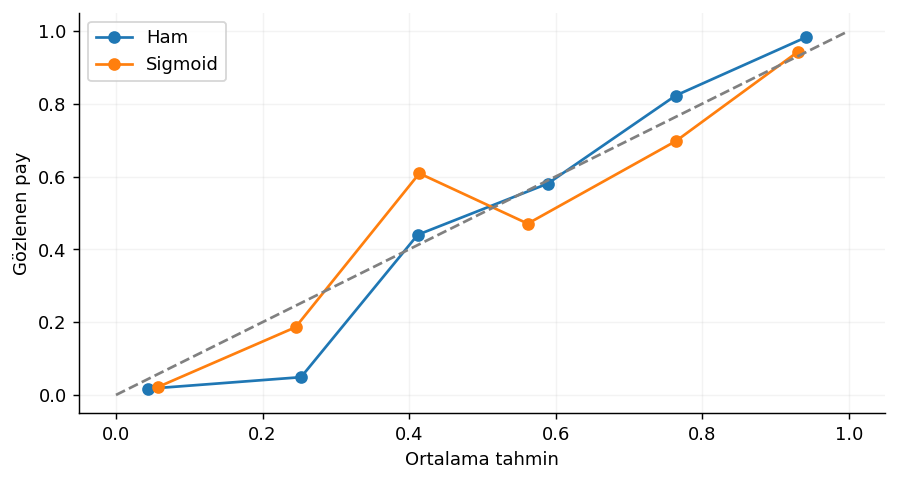

In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier
X,y=make_classification(n_samples=1200,n_features=8,n_informative=4,random_state=7);a,b,c,d=train_test_split(X,y,test_size=.35,stratify=y,random_state=7);base=RandomForestClassifier(n_estimators=60,min_samples_leaf=8,random_state=7,n_jobs=1);cal=CalibratedClassifierCV(base,method='sigmoid',cv=3);base.fit(a,c);cal.fit(a,c)
for name,m in [('Ham',base),('Sigmoid',cal)]:
 p=m.predict_proba(b)[:,1];print(name,'Brier',brier_score_loss(d,p));obs,mean=calibration_curve(d,p,n_bins=6);plt.plot(mean,obs,'o-',label=name)
plt.plot([0,1],[0,1],'--',c='gray');plt.xlabel('Ortalama tahmin');plt.ylabel('Gözlenen pay');plt.legend()

## Model karşılaştırması ve eşleştirilmiş belirsizlik

İki model aynı kayıtlarda nasıl karşılaştırılır?

**Veri:** Kod içindeki sabit tohumlu sentetik veri. Gerçek şirket verisi içermez.

**Grafiği oku:** Satırları çift olarak yeniden çekerek kayıp farkı aralığını kur.

**Yorum sınırı:** Bağımsız test kayıtları varsayılır; zaman veya müşteri kümelerinde blok/küme bootstrap gerekir.

**Alıştırma:** İki modelin aynı satırlardaki korelasyonunu artır; bağımsız çekimin neden yanlış olduğunu açıkla.

**Kabul ölçütü:** İlk çıktıyı, tek değişiklikten sonraki çıktıyı, grafikteki farkı ve yorum sınırını dört cümlede kaydet.


{'MSE_A_eksi_B': np.float64(0.3019808286429534), 'esli_bootstrap_CI95': [0.06955466381269268, 0.5414162544434127]}


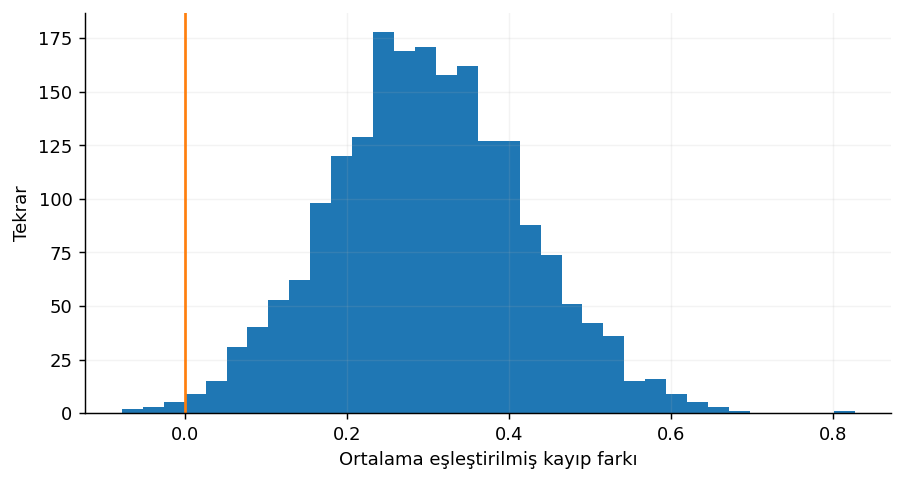

In [108]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, BayesianRidge
from sklearn.metrics import mean_squared_error, log_loss, brier_score_loss, roc_auc_score, average_precision_score
from sklearn.datasets import make_classification, make_moons
import statsmodels.api as sm
import statsmodels.formula.api as smf
rng=np.random.default_rng(20261108)
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns',8)
plt.rcParams.update({'figure.figsize':(8,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

y=rng.normal(size=250);pA=y+rng.normal(0,1,250);pB=y+rng.normal(0,.9,250);diff=(pA-y)**2-(pB-y)**2;draws=rng.choice(diff,(2000,len(diff))).mean(axis=1);print({'MSE_A_eksi_B':diff.mean(),'esli_bootstrap_CI95':np.quantile(draws,[.025,.975]).tolist()})
plt.hist(draws,bins=35);plt.axvline(0,c='tab:orange');plt.xlabel('Ortalama eşleştirilmiş kayıp farkı');plt.ylabel('Tekrar')